# WTI crude oil futures — Exploratory Data Analysis

**Dataset:** `oil.csv`  
**Nguồn:** Yahoo Finance, ticker CL=F  
**Vai trò trong dự án:** Nguồn external market cho bài toán Gold phiên kế tiếp.

## Mục tiêu phân tích

1. Hiểu cấu trúc, chất lượng, phân phối và phạm vi thời gian của nguồn dữ liệu.
2. Từ câu hỏi đặc thù của dataset, xây dựng các feature ứng viên và mô tả chúng.
3. Ghi nhận bằng chứng cần có trước khi quyết định giữ feature cho bài toán Gold phiên kế tiếp.

## Cấu trúc notebook

- **Part 1 — Data Profiling:** chỉ phân tích biến gốc.
- **Part 2 — Feature-oriented EDA:** câu hỏi → đại lượng cần đo → feature → EDA.


**Phạm vi:** snapshot EDA 2010–2026 của bốn nguồn Yahoo Finance; dữ liệu modeling 2005–2026 được xử lý riêng.

## Part 1 — Data Profiling

Phần này trả lời: dữ liệu có gì, có sạch không, phân phối cơ bản ra sao và trải dài trong thời gian nào? Chưa tạo return, MA, RSI hoặc MACD.


### 1.1 Thư viện và nguồn dữ liệu

In [1]:
from pathlib import Path



In [2]:

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/modeling/horizons').is_dir() and (p/'notebook').is_dir())
DATA_DIR = ROOT / 'data/eda_2010_2026'
FILE_NAME = 'oil.csv'
DATA_PATH = DATA_DIR / FILE_NAME
RAW_NUMERIC = ['Open', 'High', 'Low', 'Close', 'Volume']
TITLE = 'WTI crude oil futures'


pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

### 1.2 Đọc dữ liệu và chuẩn hóa định dạng

Chuẩn hóa tên Date, parse ngày và numeric trên bản sao. Đếm lỗi chuyển đổi; không impute và không xóa quan sát. Hai dòng metadata Yahoo không phải quan sát thị trường.


In [3]:

metadata = pd.read_csv(DATA_PATH, nrows=2)
print('\nThông tin metadata của file nguồn')
display(metadata)

if metadata.iloc[0, 0] == 'Ticker' and metadata.iloc[1, 0] == 'Date':
    print('Metadata đúng định dạng Ticker/Date.')
else:
    print('Cảnh báo: Metadata không đúng định dạng Ticker/Date dự kiến; cần kiểm tra cách đọc file.')

if (metadata.iloc[0, 1:] == 'CL=F').all():
    print('Ticker đúng nguồn dự kiến.')
else:
    print('Cảnh báo: Ticker không đúng nguồn dự kiến.')

raw = pd.read_csv(DATA_PATH, skiprows=[1, 2])

if set(raw.columns) == {'Price', 'Open', 'High', 'Low', 'Close', 'Volume'}:
    print('Các cột đúng schema dự kiến.')
else:
    print('Cảnh báo: Các cột trong file khác schema dự kiến; xem tên cột trước khi phân tích tiếp.')

df = raw.rename(columns={'Price': 'Date'}).copy()


original_dates = df['Date'].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
parse_failures = {'Date': int((original_dates.notna() & df['Date'].isna()).sum())}

for column in RAW_NUMERIC:
    original_values = df[column].copy()
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

input_sorted = df['Date'].is_monotonic_increasing
df = df.sort_values('Date', kind='stable').reset_index(drop=True)
print('\n5 dòng đầu của dữ liệu')
display(df.head())
print('\n5 dòng cuối của dữ liệu')
display(df.tail())


Thông tin metadata của file nguồn


,Price,Close,High,Low,Open,Volume
0,Ticker,CL=F,CL=F,CL=F,CL=F,CL=F
1,Date,NaN,NaN,NaN,NaN,NaN


Metadata đúng định dạng Ticker/Date.
Ticker đúng nguồn dự kiến.
Các cột đúng schema dự kiến.

5 dòng đầu của dữ liệu


,Date,Close,High,Low,Open,Volume
0,2010-01-04,81.510002,81.680000,79.629997,79.629997,263542
1,2010-01-05,81.769997,82.000000,80.949997,81.629997,258887
2,2010-01-06,83.180000,83.519997,80.849998,81.430000,370059
3,2010-01-07,82.660004,83.360001,82.260002,83.199997,246632
4,2010-01-08,82.750000,83.470001,81.800003,82.650002,310377



5 dòng cuối của dữ liệu


,Date,Close,High,Low,Open,Volume
4198,2026-09-14,101.389999,104.949997,100.529999,102.250000,413090
4199,2026-09-15,105.830002,106.750000,101.209999,102.010002,371490
4200,2026-09-16,102.430000,105.629997,100.970001,105.480003,301167
4201,2026-09-17,101.910004,102.470001,99.099998,102.180000,265972
4202,2026-09-18,96.080002,98.010002,94.830002,101.059998,300567


### 1.3 Kích thước và phạm vi thời gian

“Số ngày quan sát” là số Date hợp lệ khác nhau; khác với số ngày lịch giữa đầu và cuối chuỗi.


In [4]:

overview = pd.DataFrame([{
    'Rows': len(df), 'Columns_including_Date': len(df.columns),
    'Start_date': df['Date'].min(), 'End_date': df['Date'].max(),
    'Unique_observed_dates': df['Date'].nunique(),
    'Calendar_span_days': (df['Date'].max() - df['Date'].min()).days + 1,
    'Rows_removed': len(raw) - len(df), 'Originally_sorted': input_sorted
}])
print('\nTổng quan kích thước và phạm vi thời gian')
display(overview)
print('\nSố dòng quan sát theo năm')
display(df.groupby(df['Date'].dt.year).size().rename('Observed_rows').to_frame())


Tổng quan kích thước và phạm vi thời gian


,Rows,Columns_including_Date,Start_date,End_date,Unique_observed_dates,Calendar_span_days,Rows_removed,Originally_sorted
0,4203,6,2010-01-04,2026-09-18,4203,6102,0,True



Số dòng quan sát theo năm


,Observed_rows
Date,
2010,252
2011,252
2012,250
2013,252
2014,252
2015,252
2016,250
2017,251
2018,251


### 1.4 Data schema và ý nghĩa biến

Phân biệt đơn vị giá/chỉ số với khối lượng. Những mô tả nguồn chưa xác minh được ghi rõ.


In [5]:

column_meaning = {'Date': 'Nhãn ngày quan sát của nguồn, chưa xác minh giờ chốt', 'Open': 'Giá/mức chỉ số mở cửa do nguồn cung cấp', 'High': 'Giá/mức chỉ số cao nhất theo nguồn', 'Low': 'Giá/mức chỉ số thấp nhất theo nguồn', 'Close': 'Giá/mức chỉ số Close; cần xác minh close/settlement với futures', 'Volume': 'Khối lượng do nguồn cung cấp; không so sánh trực tiếp giữa các thị trường'}

column_units = {'Open': 'USD/barrel', 'High': 'USD/barrel', 'Low': 'USD/barrel', 'Close': 'USD/barrel', 'Volume': 'Source-reported volume; cần xác minh đơn vị', 'Date': 'YYYY-MM-DD'}

schema = pd.DataFrame({
    'Column': df.columns,
    'Dtype': [str(df[c].dtype) for c in df.columns],
    'Meaning': [column_meaning[c] for c in df.columns],
    'Unit': [column_units[c] for c in df.columns]
})
print('\nCấu trúc dữ liệu và ý nghĩa từng cột')
display(schema)


Cấu trúc dữ liệu và ý nghĩa từng cột


,Column,Dtype,Meaning,Unit
0,Date,datetime64[us],"Nhãn ngày quan sát của nguồn, chưa xác minh gi...",YYYY-MM-DD
1,Close,float64,Giá/mức chỉ số Close; cần xác minh close/settl...,USD/barrel
2,High,float64,Giá/mức chỉ số cao nhất theo nguồn,USD/barrel
3,Low,float64,Giá/mức chỉ số thấp nhất theo nguồn,USD/barrel
4,Open,float64,Giá/mức chỉ số mở cửa do nguồn cung cấp,USD/barrel
5,Volume,int64,Khối lượng do nguồn cung cấp; không so sánh tr...,Source-reported volume; cần xác minh đơn vị


### 1.5 Missing values, duplicates và độ phủ ngày

**Câu hỏi:** có thiếu giá trị trong các dòng đã có, có ngày trùng, hoặc có ngày cần đối chiếu lịch nguồn không?

Phân biệt **missing cell** với **ngày không có bản ghi**. Daily data không nhất thiết có bản ghi cho mọi ngày lịch. Cuối tuần được tách riêng; ngày thứ Hai–thứ Sáu vắng mặt vẫn có thể là ngày nghỉ hoặc khác biệt lịch phiên, chưa gọi là lỗi crawl.

**Thống kê và biểu đồ:** số lượng ngắn gọn, biểu đồ ngày vắng theo năm và vị trí các ngày thường vắng. Bảng chi tiết chỉ hiện tối đa 20 dòng để xem mẫu. Không fill thêm ngày hoặc giá.



Thống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu


,Missing_cells,Missing_percent,Parse_failures
Close,0,0.0,0
Date,0,0.0,0
High,0,0.0,0
Low,0,0.0,0
Open,0,0.0,0
Volume,0,0.0,0


Duplicate raw rows: 0
Duplicate normalized rows: 0
Không có ngày bị trùng.

Các dòng có ngày bị trùng


,Date,Close,High,Low,Open,Volume



Tổng số ngày lịch không có bản ghi: 1,899
Trong đó, ngày cuối tuần: 1,742
Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: 157
Các số này chưa phải số phiên bị mất dữ liệu.

Biểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm


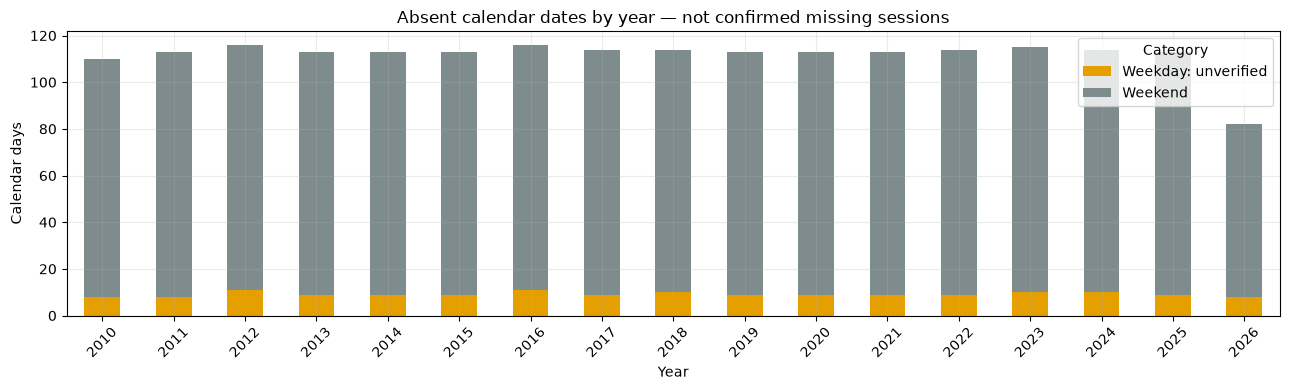


Vị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không


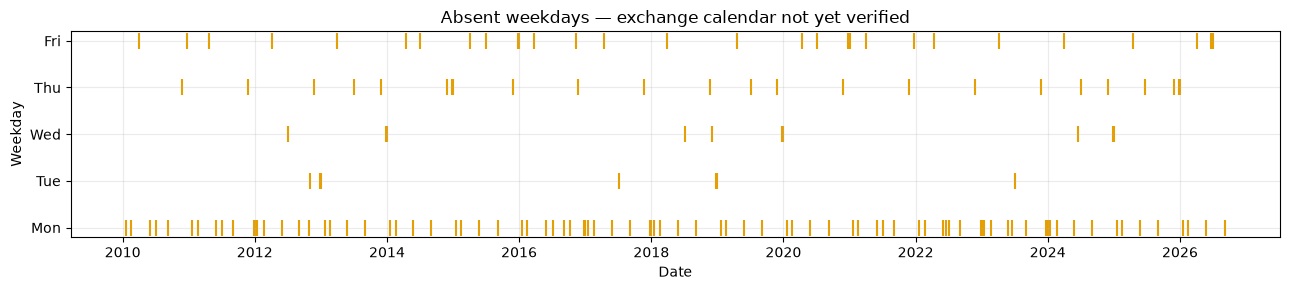


Tối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)


,Absent_date
4,2010-01-18
13,2010-02-15
26,2010-04-02
45,2010-05-31
56,2010-07-05
75,2010-09-06
98,2010-11-25
107,2010-12-24
116,2011-01-17
127,2011-02-21



10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ


,Date,Previous_date,Gap_calendar_days,Absent_dates_between
712,2012-10-31,2012-10-26,5.0,4.0
10,2010-01-19,2010-01-15,4.0,3.0
29,2010-02-16,2010-02-12,4.0,3.0
62,2010-04-05,2010-04-01,4.0,3.0
102,2010-06-01,2010-05-28,4.0,3.0
126,2010-07-06,2010-07-02,4.0,3.0
170,2010-09-07,2010-09-03,4.0,3.0
247,2010-12-27,2010-12-23,4.0,3.0
262,2011-01-18,2011-01-14,4.0,3.0
286,2011-02-22,2011-02-18,4.0,3.0


In [6]:


quality = pd.DataFrame({
    'Missing_cells': df.isna().sum(),
    'Missing_percent': df.isna().mean() * 100,
    'Parse_failures': pd.Series(parse_failures)
})
print('\nThống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu')
display(quality)
print('Duplicate raw rows:', int(raw.duplicated().sum()))
print('Duplicate normalized rows:', int(df.duplicated().sum()))

duplicate_dates = df.loc[df['Date'].notna(), 'Date'].duplicated().sum()
if duplicate_dates > 0:
    print(f'Cảnh báo: Có {duplicate_dates} ngày bị trùng.')
else:
    print('Không có ngày bị trùng.')
print('\nCác dòng có ngày bị trùng')
display(df.loc[df['Date'].notna() & df['Date'].duplicated(keep=False)])


observed_dates = pd.DatetimeIndex(df['Date'].dropna().unique()).sort_values()
if len(observed_dates) == 0:
    print('Không có ngày hợp lệ để kiểm tra độ phủ.')
else:
    calendar = pd.date_range(observed_dates.min(), observed_dates.max(), freq='D')
    absent_dates = calendar.difference(observed_dates)
    gap_table = pd.DataFrame({'Absent_date': absent_dates})
    gap_table['Weekend'] = gap_table['Absent_date'].dt.dayofweek >= 5
    weekday_gaps = gap_table.loc[~gap_table['Weekend']].copy()
    print(f'\nTổng số ngày lịch không có bản ghi: {len(gap_table):,}')
    print(f'Trong đó, ngày cuối tuần: {int(gap_table["Weekend"].sum()):,}')
    print(f'Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: {len(weekday_gaps):,}')
    print('Các số này chưa phải số phiên bị mất dữ liệu.')

    
    gap_table['Year'] = gap_table['Absent_date'].dt.year
    gap_table['Category'] = gap_table['Weekend'].map({True: 'Weekend', False: 'Weekday: unverified'})
    yearly_gaps = pd.crosstab(gap_table['Year'], gap_table['Category'])
    if not yearly_gaps.empty:
        print('\nBiểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm')
        yearly_gaps.plot.bar(stacked=True, figsize=(13, 4), color=['#e69f00', '#7f8c8d'])
        plt.title('Absent calendar dates by year — not confirmed missing sessions')
        plt.xlabel('Year')
        plt.ylabel('Calendar days')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    if weekday_gaps.empty:
        print('Không có ngày thứ Hai–thứ Sáu vắng trong phạm vi dữ liệu.')
    else:
        print('\nVị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không')
        fig, ax = plt.subplots(figsize=(13, 3))
        ax.scatter(weekday_gaps['Absent_date'], weekday_gaps['Absent_date'].dt.dayofweek,
                   color='#e69f00', marker='|', s=130)
        ax.set_yticks([0, 1, 2, 3, 4], ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])
        ax.set(title='Absent weekdays — exchange calendar not yet verified', xlabel='Date', ylabel='Weekday')
        plt.tight_layout()
        plt.show()
        print('\nTối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)')
        display(weekday_gaps[['Absent_date']].head(20))

    
    consecutive_gaps = pd.Series(observed_dates).to_frame('Date')
    consecutive_gaps['Previous_date'] = consecutive_gaps['Date'].shift(1)
    consecutive_gaps['Gap_calendar_days'] = consecutive_gaps['Date'].diff().dt.days
    consecutive_gaps['Absent_dates_between'] = consecutive_gaps['Gap_calendar_days'] - 1
    long_gaps = consecutive_gaps.loc[consecutive_gaps['Gap_calendar_days'] > 1]
    if not long_gaps.empty:
        print('\n10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ')
        display(long_gaps.nlargest(10, 'Gap_calendar_days'))

### 1.6 Giá trị bất thường và tính hợp lệ

**Mục tiêu:** phân biệt cờ kiểm tra domain với điểm ngoài phân phối chung. Cả hai đều chưa chứng minh bản ghi sai.

IQR = Q3 − Q1. Điểm ngoài [Q1 − 1.5×IQR, Q3 + 1.5×IQR] được tô cam trên chuỗi thời gian, kèm hai hàng rào nét đứt và số điểm bị flag. Một cụm cam kéo dài có thể phản ánh thay đổi mặt bằng; điểm cam riêng lẻ cần xem các ngày lân cận. IQR toàn kỳ không xét thứ tự thời gian, không dùng làm quy tắc tự xóa hoặc ngưỡng modeling.

**Thống kê và biểu đồ:** bảng cờ kiểm tra có tiêu đề và biểu đồ thời gian cho từng biến gốc. Nếu IQR=0 do dữ liệu lặp nhiều, đọc cảnh báo và không coi mọi điểm khác mức phổ biến là lỗi.

**Dữ liệu thị trường:** cần đối chiếu ý nghĩa OHLC/Close, Volume và nguồn trước khi sửa. Uy tín nguồn không thay thế kiểm tra chất lượng.



Số dòng được gắn cờ theo từng kiểm tra chất lượng


,Flagged_rows
Invalid_date,0
Nonfinite_or_missing_numeric,0
High_below_Low,0
Open_outside_range,1
Close_outside_range,0
Nonpositive_price_review,2
Negative_volume,0
Zero_volume_review,7



Chi tiết các dòng được gắn cờ cần xem xét


,Date,Close,High,Low,Open,Volume,Invalid_date,Nonfinite_or_missing_numeric,High_below_Low,Open_outside_range,Close_outside_range,Nonpositive_price_review,Negative_volume,Zero_volume_review
2588,2020-04-20,-37.630001,17.850000,-40.320000,17.730000,247947,False,False,False,False,False,True,False,False
2589,2020-04-21,10.010000,13.860000,-16.740000,-14.000000,2288230,False,False,False,False,False,True,False,False
3335,2023-04-06,80.699997,80.959999,79.650002,80.370003,0,False,False,False,False,False,False,False,True
3887,2025-06-18,75.139999,76.070000,72.940002,75.610001,0,False,False,False,False,False,False,False,True
3897,2025-07-03,67.000000,67.580002,66.529999,67.500000,0,False,False,False,False,False,False,False,True
3898,2025-07-04,66.500000,67.180000,66.040001,67.129997,0,False,False,False,False,False,False,False,True
3938,2025-08-29,64.010002,64.550003,63.880001,64.260002,0,False,False,False,False,False,False,False,True
3983,2025-11-03,61.049999,61.500000,60.509998,61.400002,0,False,False,False,False,False,False,False,True
4086,2026-04-02,111.540001,113.970001,97.500000,98.919998,0,False,False,False,False,False,False,False,True
4202,2026-09-18,96.080002,98.010002,94.830002,101.059998,300567,False,False,False,True,False,False,False,False



Open — điểm ngoài hàng rào IQR theo thời gian
1/4,203 điểm hữu hạn bị flag (0.02%).
Hàng rào dưới: 6.51; hàng rào trên: 138.13.
Ngày bị flag đầu/cuối: 2020-04-21 đến 2020-04-21.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


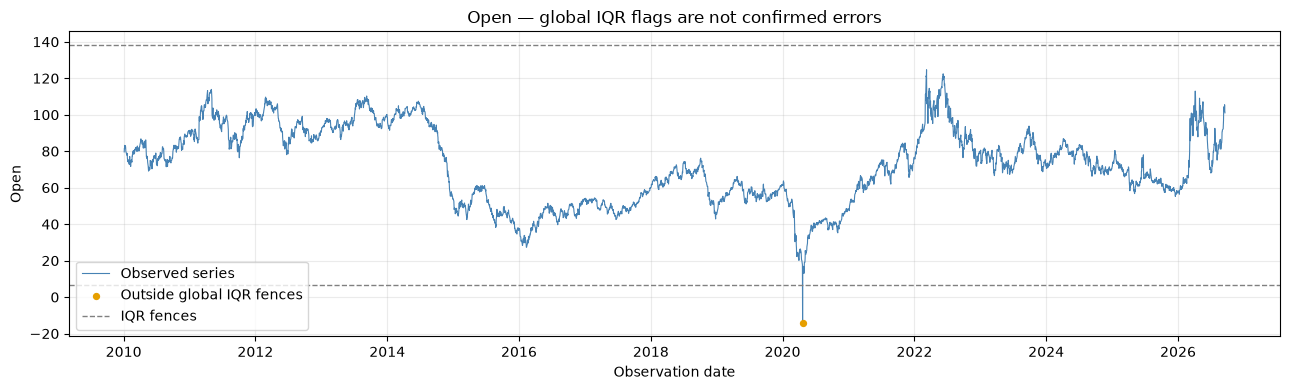


High — điểm ngoài hàng rào IQR theo thời gian
0/4,203 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: 6.47; hàng rào trên: 140.45.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


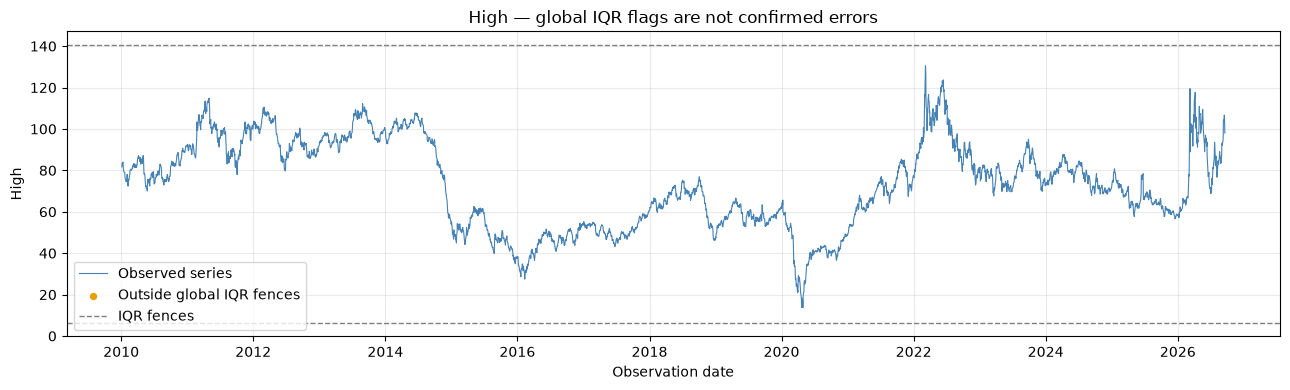


Low — điểm ngoài hàng rào IQR theo thời gian
2/4,203 điểm hữu hạn bị flag (0.05%).
Hàng rào dưới: 6.08; hàng rào trên: 136.06.
Ngày bị flag đầu/cuối: 2020-04-20 đến 2020-04-21.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


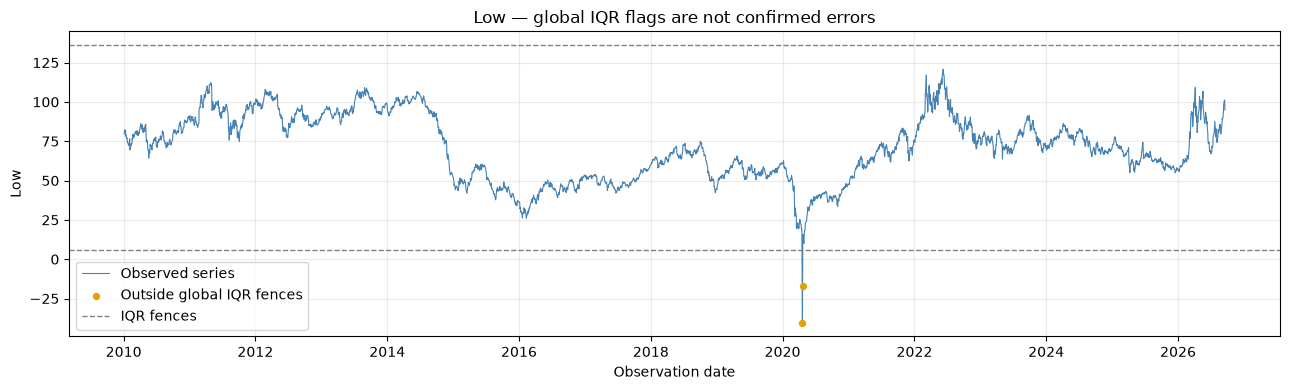


Close — điểm ngoài hàng rào IQR theo thời gian
1/4,203 điểm hữu hạn bị flag (0.02%).
Hàng rào dưới: 6.03; hàng rào trên: 138.53.
Ngày bị flag đầu/cuối: 2020-04-20 đến 2020-04-20.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


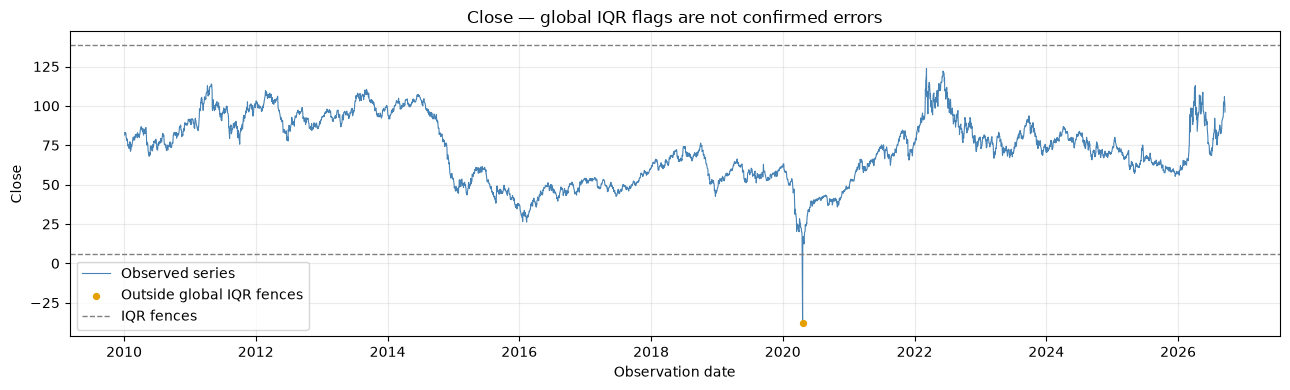


Volume — điểm ngoài hàng rào IQR theo thời gian
123/4,203 điểm hữu hạn bị flag (2.93%).
Hàng rào dưới: -91,259.25; hàng rào trên: 842,030.75.
Ngày bị flag đầu/cuối: 2016-05-11 đến 2026-03-09.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


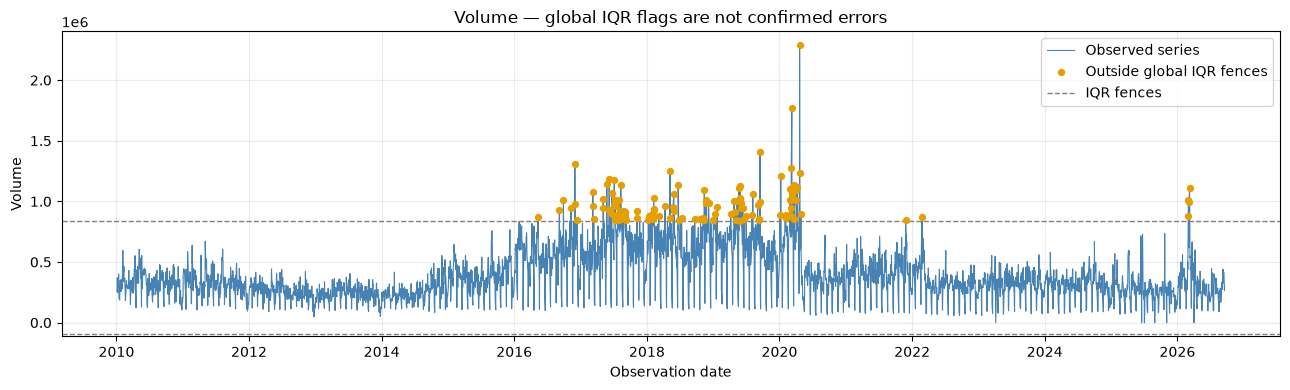

In [7]:

flags = pd.DataFrame(index=df.index)
flags['Invalid_date'] = df['Date'].isna()
flags['Nonfinite_or_missing_numeric'] = df[RAW_NUMERIC].isna().any(axis=1) | df[RAW_NUMERIC].isin([float('inf'), -float('inf')]).any(axis=1)
flags['High_below_Low'] = df['High'] < df['Low']
flags['Open_outside_range'] = (df['Open'] < df['Low']) | (df['Open'] > df['High'])
flags['Close_outside_range'] = (df['Close'] < df['Low']) | (df['Close'] > df['High'])
flags['Nonpositive_price_review'] = (df[['Open','High','Low','Close']] <= 0).any(axis=1)
flags['Negative_volume'] = df['Volume'] < 0
flags['Zero_volume_review'] = df['Volume'] == 0
print('\nSố dòng được gắn cờ theo từng kiểm tra chất lượng')
display(flags.sum().rename('Flagged_rows').to_frame())

flagged_rows = df.loc[flags.any(axis=1)].join(flags.loc[flags.any(axis=1)])
print('\nChi tiết các dòng được gắn cờ cần xem xét')
display(flagged_rows)


iqr_flags = pd.DataFrame(index=df.index)


for column in RAW_NUMERIC:
    values = df[column].replace([float('inf'), -float('inf')], float('nan'))
    valid_values = values.dropna()
    if valid_values.empty:
        print(f'\n{column}: không có giá trị hữu hạn để kiểm tra IQR.')
        continue

    
    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outside_iqr = values.notna() & ((values < lower_fence) | (values > upper_fence))
    iqr_flags[column] = outside_iqr
    flagged_count = int(outside_iqr.sum())
    flagged_percent = 100 * flagged_count / len(valid_values)

    print(f'\n{column} — điểm ngoài hàng rào IQR theo thời gian')
    print(f'{flagged_count:,}/{len(valid_values):,} điểm hữu hạn bị flag ({flagged_percent:.2f}%).')
    print(f'Hàng rào dưới: {lower_fence:,.2f}; hàng rào trên: {upper_fence:,.2f}.')
    if iqr == 0:
        print('Lưu ý: IQR = 0, quy tắc này có thể flag nhiều điểm chỉ vì dữ liệu tập trung tại một mức.')
    if flagged_count > 0:
        flagged_dates = df.loc[outside_iqr, 'Date']
        print(f'Ngày bị flag đầu/cuối: {flagged_dates.min():%Y-%m-%d} đến {flagged_dates.max():%Y-%m-%d}.')
        print('Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.')
    else:
        print('Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.')

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(df['Date'], values, color='steelblue', linewidth=0.8, label='Observed series')
    ax.scatter(df.loc[outside_iqr, 'Date'], values.loc[outside_iqr],
               color='#e69f00', s=18, zorder=3, label='Outside global IQR fences')
    ax.axhline(lower_fence, color='gray', linestyle='--', linewidth=1, label='IQR fences')
    ax.axhline(upper_fence, color='gray', linestyle='--', linewidth=1)
    ax.set_title(column + ' — global IQR flags are not confirmed errors')
    ax.set_xlabel('Observation date')
    ax.set_ylabel(column)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 1.7 Thống kê mô tả các biến gốc

Mean, median, sample standard deviation (ddof=1), min, max và quartiles. NaN/inf không tham gia thống kê hữu hạn; đã được báo riêng ở kiểm tra chất lượng.


In [8]:

raw_finite = df[RAW_NUMERIC].replace([float('inf'), -float('inf')], float('nan'))

descriptive = raw_finite.describe(percentiles=[.25, .5, .75]).T
descriptive = descriptive.rename(columns={'50%': 'median'})
print('\nThống kê mô tả các biến gốc')
display(descriptive[['count','mean','median','std','min','25%','75%','max']])


Thống kê mô tả các biến gốc


,count,mean,median,std,min,25%,75%,max
Open,4203.0,72.078917,72.059998,20.677439,-14.000000,55.870001,88.774998,1.246600e+02
High,4203.0,73.178503,73.190002,20.845669,13.690000,56.710001,90.205002,1.305000e+02
Low,4203.0,70.871290,70.910004,20.490490,-40.320000,54.820002,87.314999,1.207900e+02
Close,4203.0,72.045689,71.989998,20.703288,-37.630001,55.720001,88.844997,1.237000e+02
Volume,4203.0,390371.652153,339506.000000,199978.940136,0.000000,258724.500000,492047.000000,2.288230e+06


### 1.8 Phân phối các biến gốc

Mỗi biến có histogram và boxplot riêng. Giữ toàn bộ giá trị hữu hạn, không cắt đuôi hoặc winsorize. Đây chưa phải phân phối return.


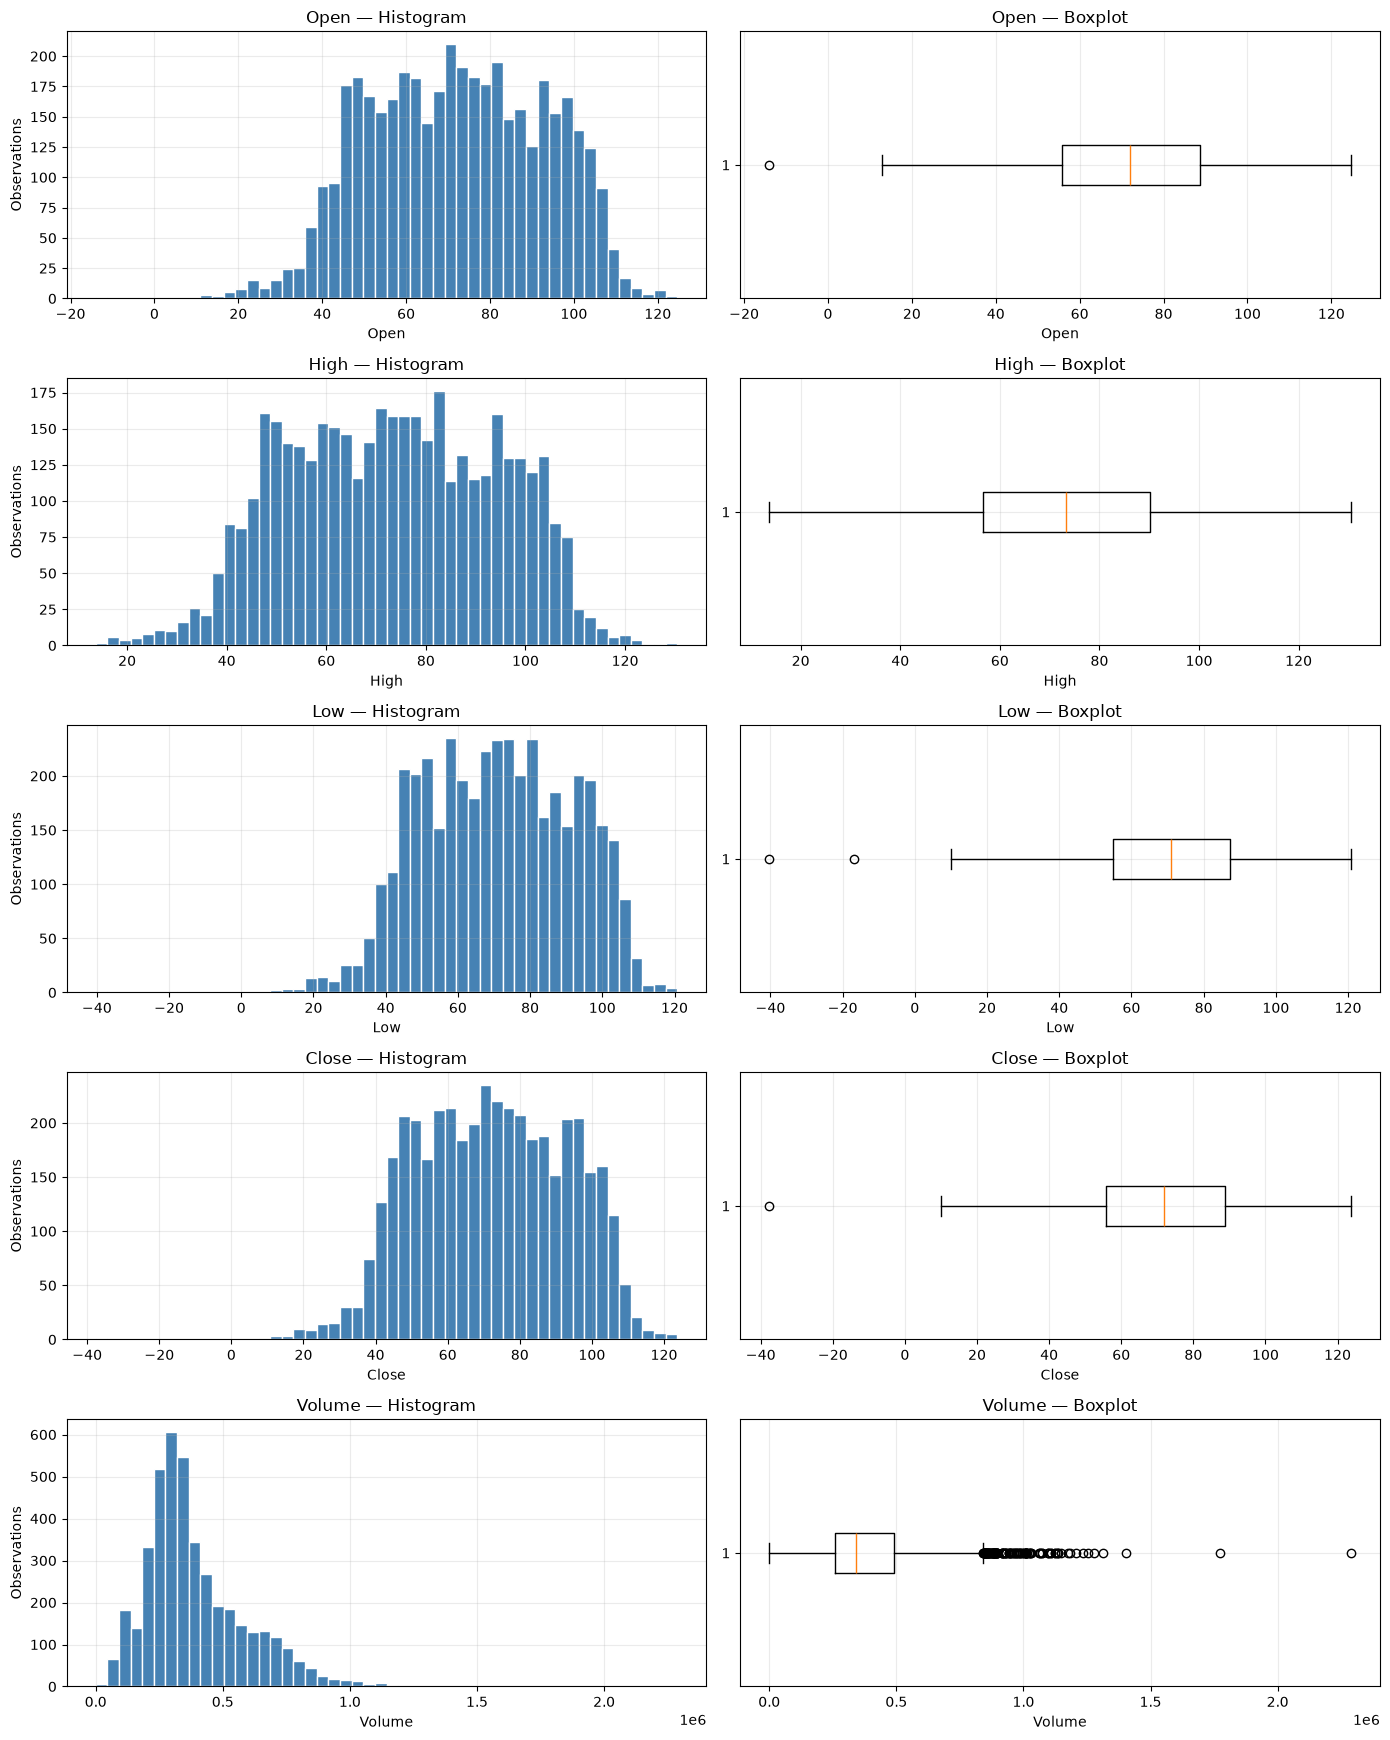

In [9]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 2, figsize=(14, 3.5 * len(RAW_NUMERIC)), squeeze=False)
for row, column in enumerate(RAW_NUMERIC):
    values = raw_finite[column].dropna()
    if len(values):
        axes[row, 0].hist(values, bins=50, color='steelblue', edgecolor='white')
        axes[row, 1].boxplot(values, orientation='horizontal')
    axes[row, 0].set_title(column + ' — Histogram')
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel('Observations')
    axes[row, 1].set_title(column + ' — Boxplot')
    axes[row, 1].set_xlabel(column)
plt.tight_layout()
plt.show()

### 1.9 Diễn biến theo thời gian

Vẽ từng biến gốc riêng, giữ đơn vị riêng. Bảng theo năm hỗ trợ quan sát thay đổi quy mô. Một bước nhảy trên biểu đồ chỉ là candidate shock/structural break; cần xác minh trước khi gán nguyên nhân.


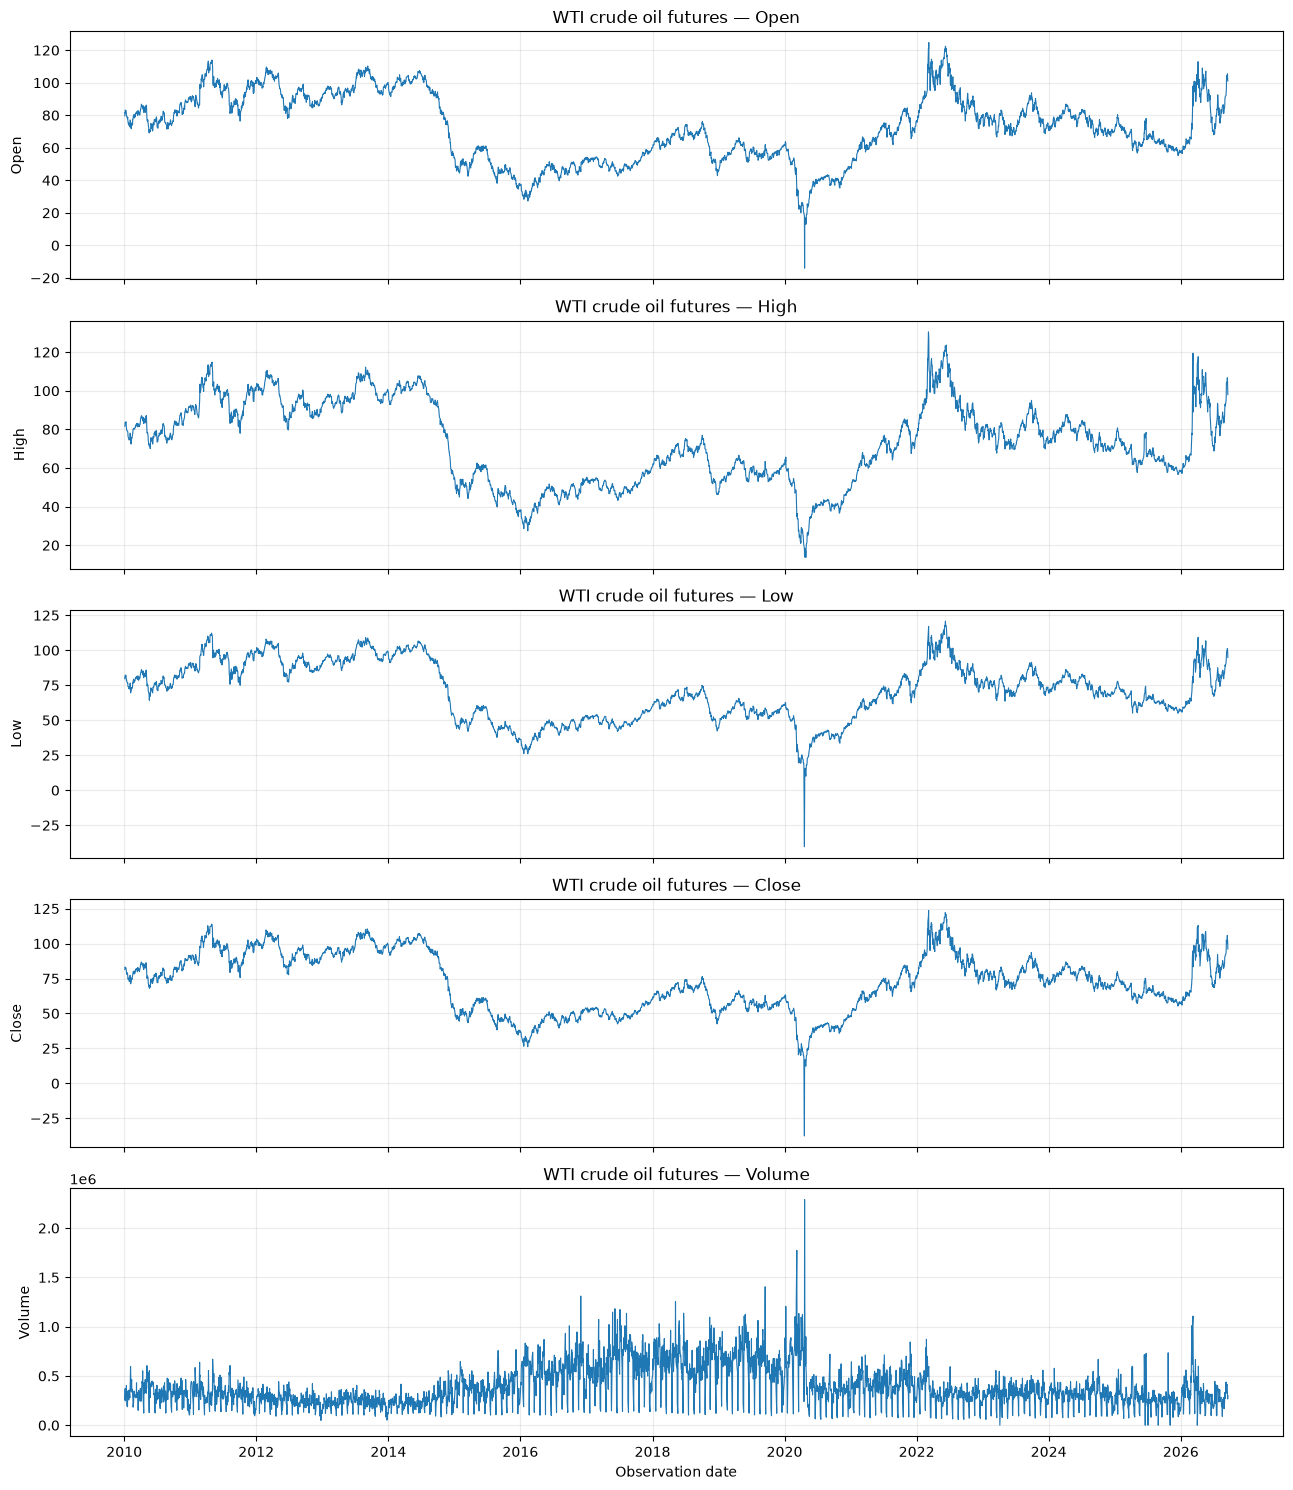


Thống kê các biến gốc theo năm


Open                                                          High  \
     count       mean     median        std        min         max count   
Date                                                                       
2010   252  79.571706  79.634998   5.108451  69.110001   91.269997   252   
2011   252  95.122143  95.950001   8.038736  76.400002  113.889999   252   
2012   250  94.267800  92.895000   7.705367  78.110001  109.669998   250   
2013   252  97.988690  96.630001   5.437211  86.389999  110.279999   252   
2014   252  93.043809  97.684998  13.144242  53.720001  107.419998   252   
2015   252  48.840278  48.000000   6.732017  34.580002   61.230000   252   
2016   250  43.406840  45.035000   6.656247  27.299999   53.930000   250   
2017   251  50.854263  50.630001   3.857135  42.549999   59.910000   251   
2018   251  64.993506  66.169998   6.550581  42.849998   76.180000   251   
2019   252  57.042143  56.720001   3.735165  45.799999   66.169998   252   
2020   253  39.471779  40.580002  10.794754 -14.000000   63.709999   253   
2021   252  68.007024  68.440002   8.294342  47.380001   84.529999   252   
2022   251  94.375339  91.750000  12.468534  71.790001  124.660004   251   
2023   250  77.726560  77.155003   6.032712  66.620003   93.779999   250   
2024   252  75.792540  76.209999   5.172259  66.279999   86.860001   252   
2025   252  64.845159  63.719999   5.357420  55.230000   80.400002   252   
2026   179  83.358380  84.980003  14.766938  56.419998  112.959999   179   

                                       ...      Close                        \
           mean     median        std  ...     median        std        min   
Date                                   ...                                    
2010  80.599365  80.565002   4.989812  ...  79.740002   5.188349  68.010002   
2011  96.514643  97.620003   7.962402  ...  95.834999   8.076783  75.669998   
2012  95.306440  93.875000   7.624265  ...  92.695004   7.673037  77.690002   
2013  98.835397  97.139999   5.477385  ...  96.610001   5.426559  86.680000   
2014  93.849286  98.584999  13.025726  ...  97.744999  13.367084  53.270000   
2015  49.818651  49.039999   6.767259  ...  47.955000   6.790013  34.730000   
2016  44.271760  46.080000   6.491733  ...  45.059999   6.704374  26.209999   
2017  51.451434  50.930000   3.835055  ...  50.419998   3.910969  42.529999   
2018  65.834582  67.000000   6.464187  ...  66.220001   6.682116  42.529999   
2019  57.845913  57.490000   3.582569  ...  56.740000   3.685715  46.540001   
2020  40.581107  41.160000  10.043928  ...  40.630001  11.347522 -37.630001   
2021  69.088810  69.485001   8.311625  ...  68.400002   8.218980  47.619999   
2022  96.609562  93.739998  12.936314  ...  91.930000  12.392960  71.019997   
2023  78.885520  78.074997   5.989190  ...  77.084999   6.008919  66.739998   
2024  76.808690  77.440002   5.077691  ...  76.205002   5.194764  65.750000   
2025  65.762341  64.495003   5.465703  ...  63.664999   5.291393  55.270000   
2026  85.695475  86.790001  15.610067  ...  84.879997  14.600317  55.990002   

                 Volume                                                  \
             max  count           mean    median            std     min   
Date                                                                      
2010   91.510002    252  329039.075397  328383.5   91301.608099  104321   
2011  113.930000    252  325648.238095  323170.0   98992.704359   95270   
2012  109.769997    250  257245.684000  260641.5   66896.919846   48516   
2013  110.529999    252  239347.023810  241665.0   61725.195012   51877   
2014  107.260002    252  253093.099206  247244.5   80054.850905   83702   
2015   61.430000    252  381277.964286  374473.5  118955.716548  102597   
2016   54.060001    250  557731.020000  562942.0  175128.592390   98293   
2017   60.419998    251  623069.760956  637035.0  215174.069516  122593   
2018   76.410004    251  623179.637450  650324.0  205905.146152  103220   
2019

In [10]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 1, figsize=(13, 3 * len(RAW_NUMERIC)), squeeze=False, sharex=True)
for row, column in enumerate(RAW_NUMERIC):
    axes[row, 0].plot(df['Date'], raw_finite[column], linewidth=.8)
    axes[row, 0].set_title(TITLE + ' — ' + column)
    axes[row, 0].set_ylabel(column)
axes[-1, 0].set_xlabel('Observation date')
plt.tight_layout()
plt.show()

annual_raw = raw_finite.groupby(df['Date'].dt.year).agg(['count','mean','median','std','min','max'])
print('\nThống kê các biến gốc theo năm')
display(annual_raw)

**Điểm cần chú ý riêng:** giá Oil không dương cần điều tra nhưng không tự xem là lỗi hoặc xóa. Kiểm tra OHLC và ngữ nghĩa chuỗi futures; chưa tính return trong Part 1.


## Part 2 — Feature-oriented EDA

Phân tích từng feature của **Oil** theo thứ tự: câu hỏi → đại lượng cần đo → cách tính → bảng/biểu đồ.

Cấu hình EDA: lag **1/2/3/5 phiên**, volatility **5/20/60 phiên**, MA **5/20/50 phiên**.

Các feature được tạo trên bản sao `oil`, còn `df` giữ các biến gốc. Biến động chính là thay đổi giá có dấu `Price_Change = Close.diff()` trên toàn chuỗi. Price_Change, các lag và volatility đều dùng USD/barrel. MA và Distance to MA cũng dùng USD/barrel; distance là chênh lệch có dấu Close − MA. Lag và cửa sổ tính theo phiên quan sát của chính nguồn.


### 2.0 Chuẩn bị dữ liệu và cấu hình

Giữ `df` của Part 1 nguyên vẹn, tạo bản sao `oil`. Kiểm tra điều kiện tính feature bằng thông báo. Nếu Date thiếu/trùng hoặc Close thiếu/không hữu hạn, các cell tính toán sẽ in lý do bỏ qua thay vì tạo kết quả không đáng tin. OHLC được kiểm tra riêng ở Part 1.


In [11]:

oil = df.copy()


LAGS = [1, 2, 3, 5]
VOL_WINDOWS = [5, 20, 60]
MA_WINDOWS = [5, 20, 50]


feature_ready = True
if oil.empty:
    print('Cảnh báo: Dữ liệu rỗng; chưa tính feature.')
    feature_ready = False
if oil['Date'].isna().any() or oil['Date'].duplicated().any():
    print('Cảnh báo: Date thiếu hoặc trùng; cần kiểm tra lại Part 1.')
    feature_ready = False
if not oil['Date'].is_monotonic_increasing:
    print('Cảnh báo: Date chưa tăng dần; cần kiểm tra thứ tự ở Part 1.')
    feature_ready = False
invalid_close = oil['Close'].isna() | oil['Close'].isin([float('inf'), -float('inf')])
if invalid_close.any():
    print(f'Cảnh báo: Có {int(invalid_close.sum())} Close thiếu hoặc không hữu hạn.')
    feature_ready = False
if feature_ready:
    print(f'Dữ liệu đủ điều kiện tính feature trên {len(oil):,} phiên quan sát.')
    print('Các dòng warm-up sẽ để NaN, không fill bằng 0.')
else:
    print('Các cell feature bên dưới sẽ bỏ qua phép tính cho tới khi đầu vào được xử lý.')


feature_columns = []

Dữ liệu đủ điều kiện tính feature trên 4,203 phiên quan sát.
Các dòng warm-up sẽ để NaN, không fill bằng 0.


### 2.1 Signed Price Change (ΔP)

**Câu hỏi:** Giá Oil hôm nay tăng hoặc giảm bao nhiêu USD/barrel so với phiên quan sát trước?

**Ý nghĩa:** Đo chiều và độ lớn thay đổi giá, kể cả khi Close âm hoặc bằng 0. Dùng cùng một công thức trên toàn chuỗi.

**Cách tính và đơn vị:** `Price_Change(t) = Close(t) − Close(t−1)` bằng `diff()`, đơn vị USD/barrel. Dòng đầu thiếu vì chưa có phiên trước; không forward-fill.

**Thống kê và biểu đồ:** Thống kê, line chart, histogram/boxplot và 10 phiên có |ΔP| lớn nhất. Giữ nguyên dấu ở bảng và biểu đồ; trị tuyệt đối chỉ dùng xếp hạng độ lớn.


**Lý do chọn ΔP:** percentage return quanh 20–21/04/2020 có dấu và độ lớn khó diễn giải khi giá đi qua mức âm. ΔP dương luôn biểu thị Close tăng, ΔP âm biểu thị Close giảm. Đây là thay đổi giá theo USD/barrel, không phải tỷ suất lợi nhuận hoặc lợi nhuận giao dịch thực tế. ΔP không chuẩn hóa theo mặt bằng giá, nên cần thận trọng khi so sánh các giai đoạn hoặc thị trường khác nhau.



Thống kê Signed Price Change — đơn vị USD/barrel mỗi phiên


,Price change (USD/barrel)
count,4202.000000
mean,0.003467
std,2.031344
min,-55.900002
1%,-4.749800
25%,-0.827501
50%,0.070000
75%,0.870002
99%,4.209999
max,47.640001


Số thay đổi giá thiếu (phiên đầu): 1

10 phiên có độ lớn Signed Price Change cao nhất


,Date,Close,Price change (USD/barrel)
2559,2020-03-09,31.129999,-10.150000
2588,2020-04-20,-37.630001,-55.900002
2589,2020-04-21,10.010000,47.640001
2994,2021-11-26,68.150002,-10.239998
3064,2022-03-09,108.699997,-15.000000
4069,2026-03-10,83.449997,-11.320000
4078,2026-03-23,88.129997,-10.190002
4086,2026-04-02,111.540001,11.419998
4089,2026-04-08,94.410004,-18.539993
4096,2026-04-17,83.849998,-10.840004


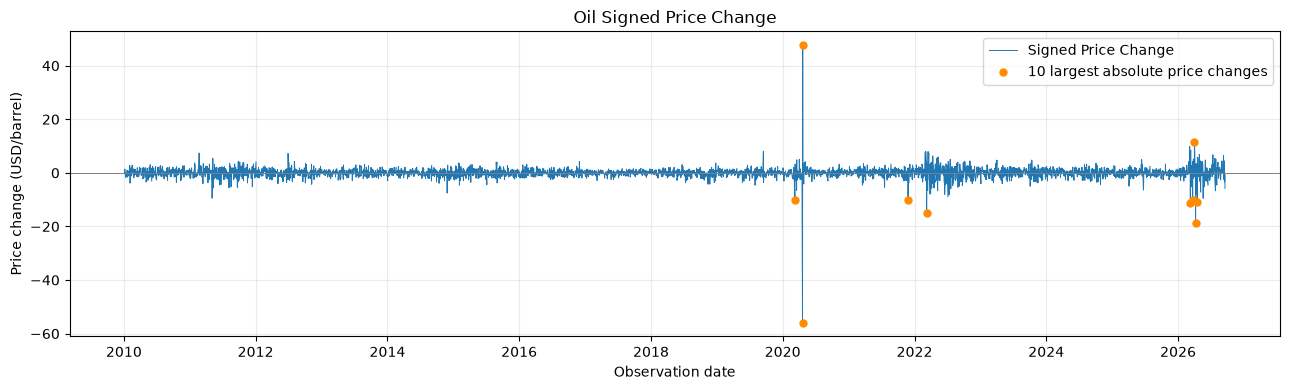

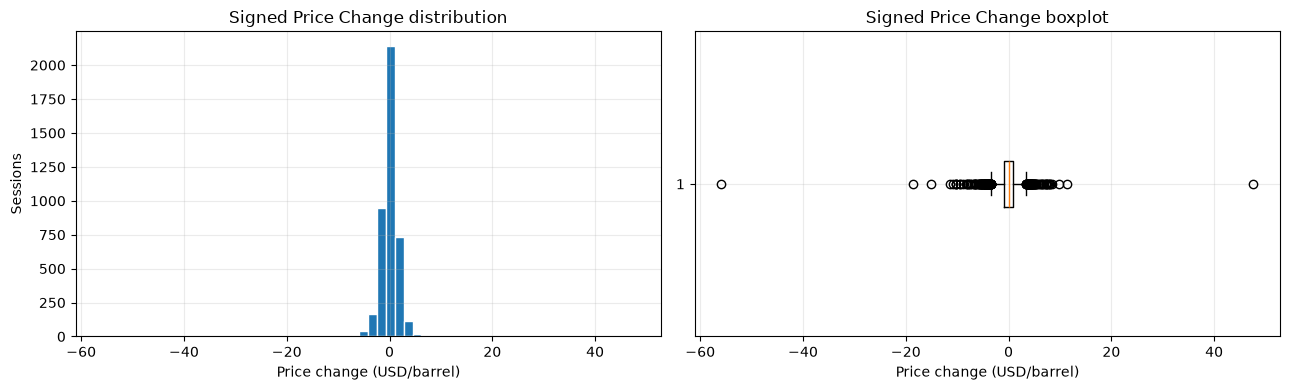

In [12]:
if feature_ready:
    
    oil['Price_Change'] = oil['Close'].diff()
    feature_columns.append('Price_Change')
    
    previous_close = oil['Close'].shift(1)
    oil['Nonpositive_Pair'] = (oil['Close'] <= 0) | (previous_close <= 0)
    price_change = oil['Price_Change']

    print('\nThống kê Signed Price Change — đơn vị USD/barrel mỗi phiên')
    display(price_change.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame('Price change (USD/barrel)'))
    print('Số thay đổi giá thiếu (phiên đầu):', int(oil['Price_Change'].isna().sum()))

    
    extreme_rows = oil['Price_Change'].abs().nlargest(10).index
    extreme_table = oil.loc[extreme_rows, ['Date', 'Close']].copy()
    extreme_table['Price change (USD/barrel)'] = price_change.loc[extreme_rows]
    print('\n10 phiên có độ lớn Signed Price Change cao nhất')
    display(extreme_table.sort_values('Date'))

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(oil['Date'], price_change, linewidth=.7, label='Signed Price Change')
    ax.scatter(oil.loc[extreme_rows, 'Date'], price_change.loc[extreme_rows],
               color='darkorange', s=25, label='10 largest absolute price changes', zorder=3)
    ax.axhline(0, color='gray', linewidth=.7)
    ax.set(title='Oil Signed Price Change', xlabel='Observation date', ylabel='Price change (USD/barrel)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(price_change.dropna(), bins=60, edgecolor='white')
    axes[0].set(title='Signed Price Change distribution', xlabel='Price change (USD/barrel)', ylabel='Sessions')
    axes[1].boxplot(price_change.dropna(), orientation='horizontal')
    axes[1].set(title='Signed Price Change boxplot', xlabel='Price change (USD/barrel)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Signed Price Change: kiểm tra thông báo ở mục 2.0.')

### 2.2 Lagged Price Change

**Câu hỏi:** Biến động các phiên trước có đi cùng quán tính hoặc đảo chiều trong chính Oil không?

**Ý nghĩa:** Đặt giả thuyết momentum/reversal từ lịch sử, chưa kiểm tra khả năng dự báo Gold t+1.

**Cách tính và đơn vị:** `Price_Change_Lag_k(t) = Price_Change(t−k)` bằng `shift(k)`, k = 1,2,3,5 phiên. Đơn vị USD/barrel; đây không phải số ngày lịch.

**Thống kê và biểu đồ:** Bảng mapping ngày hiện tại/ngày nguồn, số cặp hợp lệ, correlation nội chuỗi và scatter từng lag với ΔP hiện tại.



Lag 1 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Price Change (USD/barrel)
0,2010-01-04,NaT,NaN
1,2010-01-05,2010-01-04,NaN
2,2010-01-06,2010-01-05,0.259995
3,2010-01-07,2010-01-06,1.410004
4,2010-01-08,2010-01-07,-0.519997
5,2010-01-11,2010-01-08,0.089996
6,2010-01-12,2010-01-11,-0.230003
7,2010-01-13,2010-01-12,-1.729996



Lag 2 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Price Change (USD/barrel)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,2010-01-04,NaN
3,2010-01-07,2010-01-05,0.259995
4,2010-01-08,2010-01-06,1.410004
5,2010-01-11,2010-01-07,-0.519997
6,2010-01-12,2010-01-08,0.089996
7,2010-01-13,2010-01-11,-0.230003



Lag 3 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Price Change (USD/barrel)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,2010-01-04,NaN
4,2010-01-08,2010-01-05,0.259995
5,2010-01-11,2010-01-06,1.410004
6,2010-01-12,2010-01-07,-0.519997
7,2010-01-13,2010-01-08,0.089996



Lag 5 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Price Change (USD/barrel)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,NaT,NaN
4,2010-01-08,NaT,NaN
5,2010-01-11,2010-01-04,NaN
6,2010-01-12,2010-01-05,0.259995
7,2010-01-13,2010-01-06,1.410004


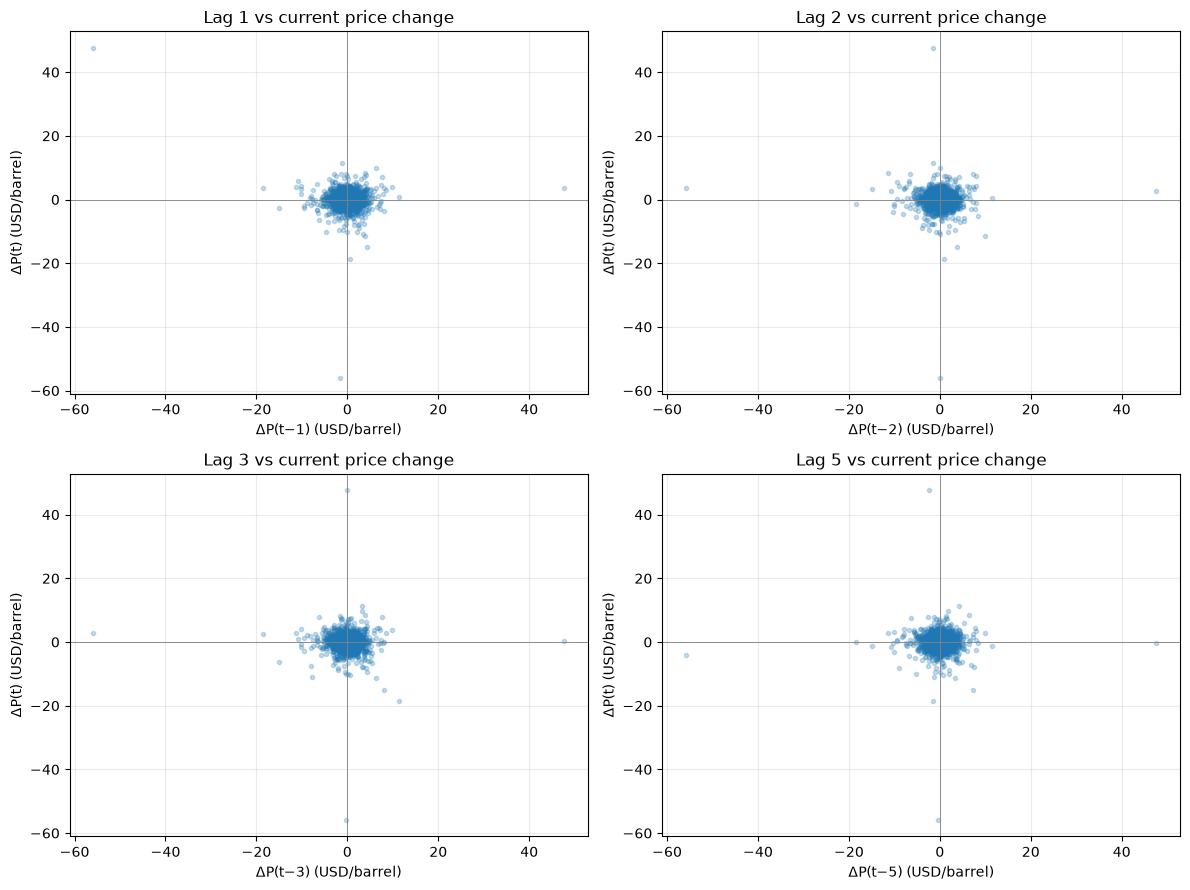


Tóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag


,Lag (sessions),Valid pairs,Missing lag values,Correlation with current price change
0,1,4201,2,-0.144774
1,2,4200,3,-0.030368
2,3,4199,4,-0.034957
3,5,4197,6,0.002383


In [13]:
if feature_ready:
    lag_summary = []
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for lag, ax in zip(LAGS, axes.flat):
        
        column = f'Price_Change_Lag_{lag}'
        oil[column] = oil['Price_Change'].shift(lag)
        feature_columns.append(column)

        
        mapping = oil[['Date']].copy()
        mapping['Source_date'] = oil['Date'].shift(lag)
        mapping['Lagged Price Change (USD/barrel)'] = oil[column]
        print(f'\nLag {lag} phiên — 8 dòng đầu của mapping ngày nguồn')
        display(mapping.head(8))

        
        pair = oil[[column, 'Price_Change']].dropna()
        lag_summary.append({'Lag (sessions)': lag, 'Valid pairs': len(pair),
                            'Missing lag values': int(oil[column].isna().sum()),
                            'Correlation with current price change': pair[column].corr(pair['Price_Change'])})
        ax.scatter(pair[column], pair['Price_Change'], s=9, alpha=.25)
        ax.axhline(0, color='gray', linewidth=.6)
        ax.axvline(0, color='gray', linewidth=.6)
        ax.set(title=f'Lag {lag} vs current price change', xlabel=f'ΔP(t−{lag}) (USD/barrel)', ylabel='ΔP(t) (USD/barrel)')
    plt.tight_layout()
    plt.show()
    print('\nTóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag')
    display(pd.DataFrame(lag_summary))
else:
    print('Chưa tính Lagged Price Change: kiểm tra mục 2.0.')

### 2.3 Rolling Volatility

**Câu hỏi:** Thị trường gần đây đang yên bình hay biến động mạnh?

**Ý nghĩa:** Mô tả trạng thái rủi ro/biến động của Oil qua các horizon khác nhau.

**Cách tính và đơn vị:** Độ lệch chuẩn mẫu (`ddof=1`) của Price_Change trong 5/20/60 phiên gần nhất, gồm t. `min_periods=window`; đơn vị USD/barrel, không annualize. Tên cột: `Price_Change_Volatility_w`.

**Thống kê và biểu đồ:** Biểu đồ ba đường volatility, thống kê và số dòng warm-up, boxplot để so độ phân tán.


**Cách đọc Oil Volatility:** độ lệch chuẩn của ΔP mô tả độ phân tán thay đổi giá theo USD/barrel. Giá âm không gây chia cho mẫu số âm/0 trong công thức này; các cú nhảy giá lớn vẫn có thể làm volatility cao. Bảng cửa sổ chứa cặp giá không dương chỉ cung cấp bối cảnh sự kiện, không xác định cửa sổ sai hoặc cần loại.



Rolling Volatility — thống kê theo USD/barrel, chưa annualize


,count,mean,std,min,25%,50%,75%,max
Price_Change_Volatility_5,4198.0,1.439690,1.530387,0.143982,0.816511,1.168546,1.668325,36.797690
Price_Change_Volatility_20,4183.0,1.550167,1.340014,0.492662,0.998911,1.261147,1.691261,17.038940
Price_Change_Volatility_60,4143.0,1.623189,1.226610,0.679809,1.069346,1.330495,1.678541,9.916392


Price_Change_Volatility_5: 5 dòng thiếu do warm-up.
Price_Change_Volatility_20: 20 dòng thiếu do warm-up.
Price_Change_Volatility_60: 60 dòng thiếu do warm-up.


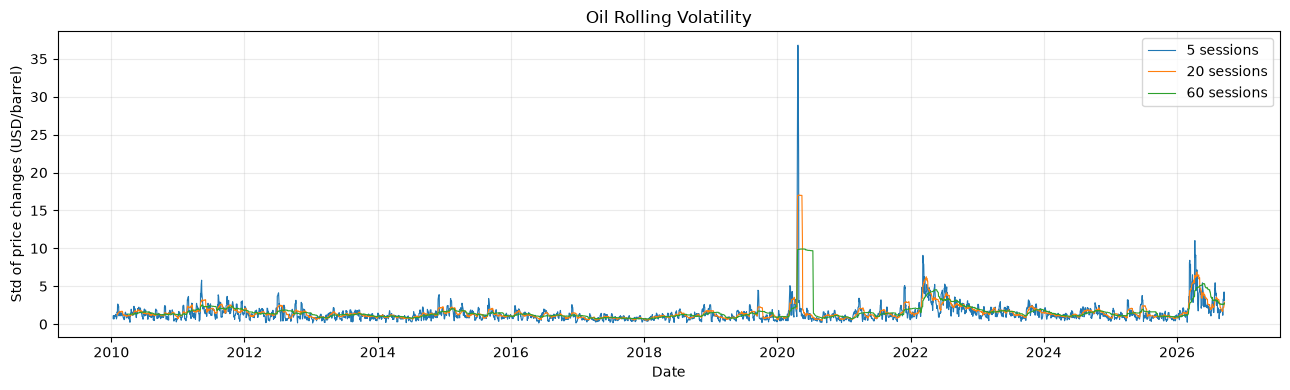

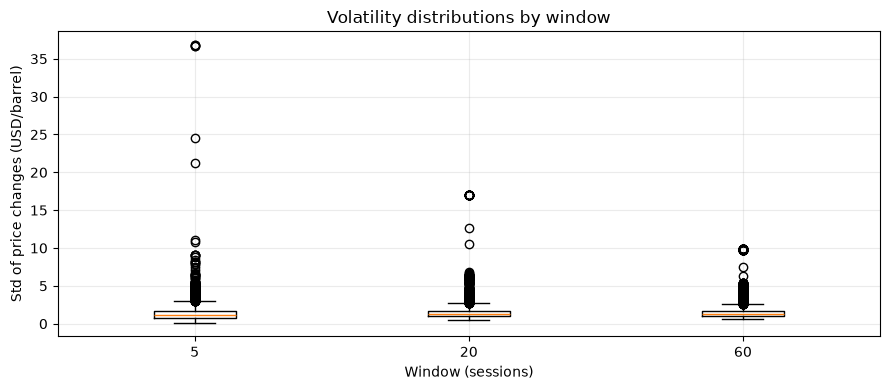

In [14]:
if feature_ready:
    volatility_names = []
    for window in VOL_WINDOWS:
        
        column = f'Price_Change_Volatility_{window}'
        oil[column] = oil['Price_Change'].rolling(window=window, min_periods=window).std(ddof=1)
        volatility_names.append(column)
        feature_columns.append(column)

    print('\nRolling Volatility — thống kê theo USD/barrel, chưa annualize')
    display((oil[volatility_names]).describe().T)
    for column in volatility_names:
        print(f'{column}: {int(oil[column].isna().sum())} dòng thiếu do warm-up.')

    fig, ax = plt.subplots(figsize=(13, 4))
    for window, column in zip(VOL_WINDOWS, volatility_names):
        ax.plot(oil['Date'], oil[column], linewidth=.8, label=f'{window} sessions')
    ax.set(title='Oil Rolling Volatility', xlabel='Date', ylabel='Std of price changes (USD/barrel)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    box_values = [(oil[column].dropna()).tolist() for column in volatility_names]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(box_values, tick_labels=[str(w) for w in VOL_WINDOWS])
    ax.set(title='Volatility distributions by window', xlabel='Window (sessions)', ylabel='Std of price changes (USD/barrel)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Rolling Volatility: kiểm tra mục 2.0.')

In [15]:
if feature_ready:
    window_review = []
    for window in VOL_WINDOWS:
        
        affected_pairs = oil['Nonpositive_Pair'].rolling(window, min_periods=window).sum()
        window_review.append({'Window': window, 'Windows containing nonpositive pairs': int((affected_pairs > 0).sum())})
    print('\nCác cửa sổ chứa cặp giá không dương — bối cảnh sự kiện, không phải lỗi ΔP')
    display(pd.DataFrame(window_review))


Các cửa sổ chứa cặp giá không dương — bối cảnh sự kiện, không phải lỗi ΔP


,Window,Windows containing nonpositive pairs
0,5,6
1,20,21
2,60,61


### 2.4 Moving Average / Distance to MA

**Câu hỏi:** Giá hiện tại cao hay thấp so với mặt bằng gần đây?

**Ý nghĩa:** MA mô tả trend; khoảng cách có dấu cho biết Close cao/thấp hơn MA bao nhiêu USD/barrel.

**Cách tính và đơn vị:** `MA_w = rolling mean(Close, w)` với w = 5/20/50; `Distance_to_MA_w = Close − MA_w`. MA và distance đều dùng USD/barrel. Giữ dấu, không dùng abs() và không chia cho MA.

**Thống kê và biểu đồ:** Close và MA toàn kỳ, góc nhìn 120 phiên cuối để dễ phân biệt các đường, distance theo thời gian và thống kê theo USD/barrel. 120 phiên chỉ là phạm vi hiển thị.


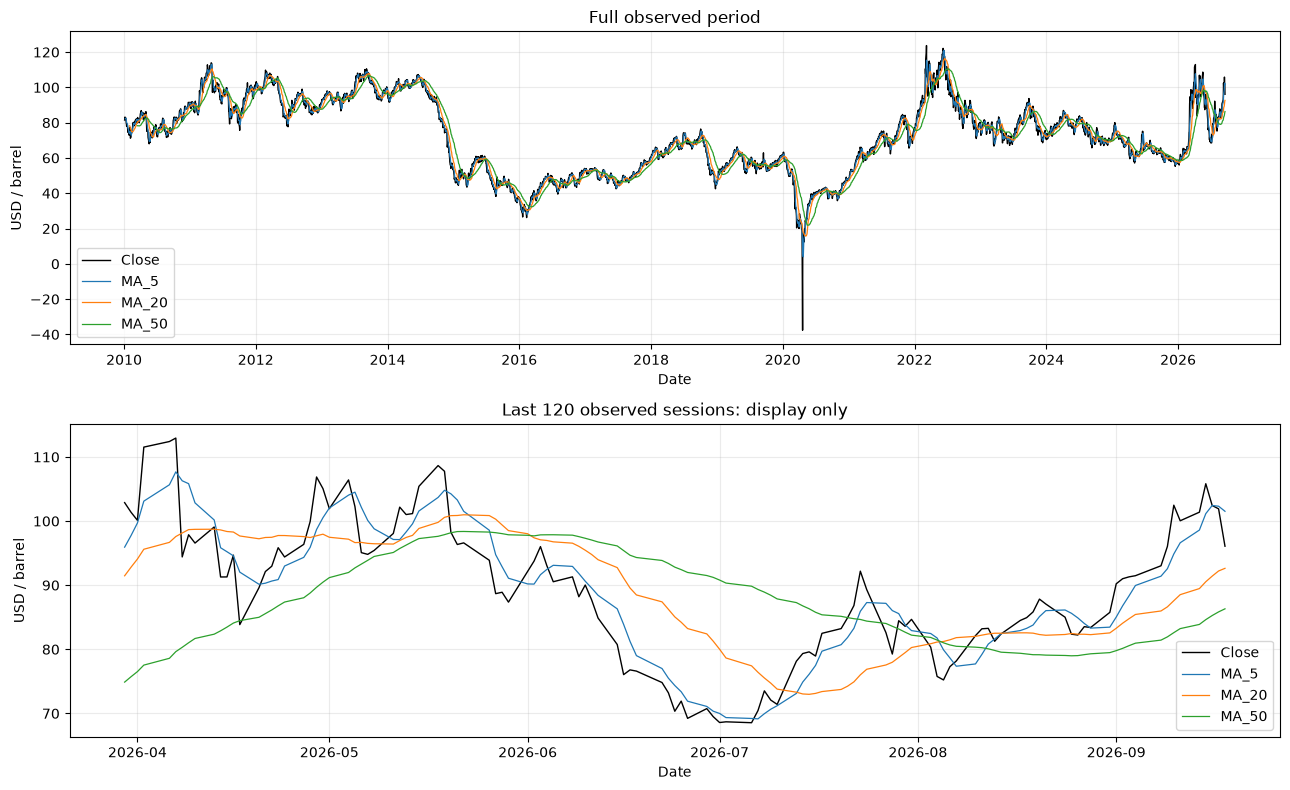

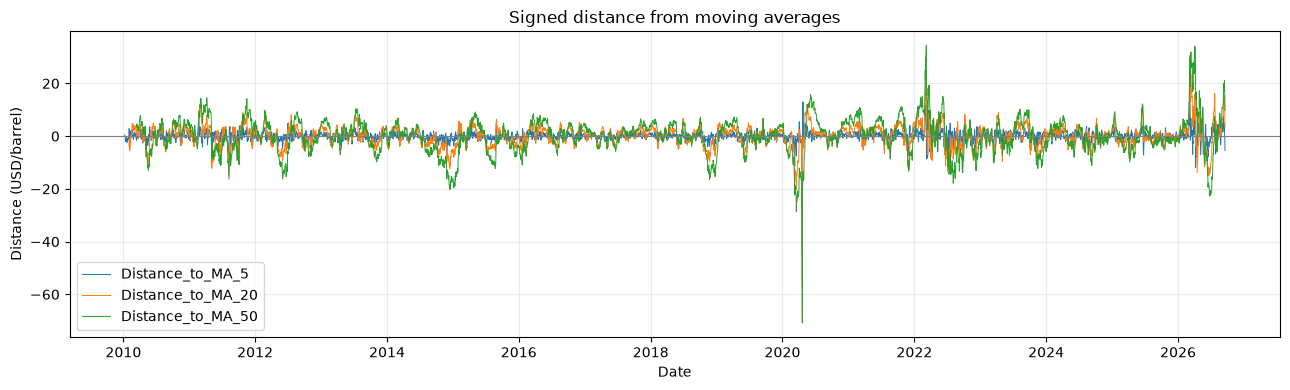


Distance to MA — thống kê theo USD/barrel


,count,mean,std,min,25%,50%,75%,max
Distance_to_MA_5,4199.0,0.008360,1.958684,-45.728001,-0.916000,0.085999,0.988000,13.020001
Distance_to_MA_20,4184.0,0.045779,4.002540,-57.178501,-2.108624,0.303500,2.346998,25.147497
Distance_to_MA_50,4154.0,0.066961,6.522053,-70.892201,-3.133549,0.402601,3.929948,34.473997



MA — thống kê theo USD/barrel


,count,mean,std,min,25%,50%,75%,max
MA_5,4199.0,72.027580,20.635881,3.9200,55.779000,71.889999,88.944001,120.926001
MA_20,4184.0,71.971043,20.488974,15.7090,55.563125,72.233501,88.577125,116.281000
MA_50,4154.0,71.906130,20.235392,21.8724,55.672850,72.340400,88.659050,110.473800


In [16]:
if feature_ready:
    ma_names = []
    distance_names = []
    for window in MA_WINDOWS:
        
        ma_column = f'MA_{window}'
        distance_column = f'Distance_to_MA_{window}'
        oil[ma_column] = oil['Close'].rolling(window=window, min_periods=window).mean()
        
        oil[distance_column] = oil['Close'] - oil[ma_column]
        ma_names.append(ma_column)
        distance_names.append(distance_column)
        feature_columns.extend([ma_column, distance_column])

    
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))
    for ax, view, label in [(axes[0], oil, 'Full observed period'),
                            (axes[1], oil.tail(120), 'Last 120 observed sessions: display only')]:
        ax.plot(view['Date'], view['Close'], color='black', linewidth=1, label='Close')
        for column in ma_names:
            ax.plot(view['Date'], view[column], linewidth=.9, label=column)
        ax.set(title=label, xlabel='Date', ylabel='USD / barrel')
        ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(13, 4))
    for column in distance_names:
        ax.plot(oil['Date'], oil[column], linewidth=.7, label=column)
    ax.axhline(0, color='gray', linewidth=.8)
    ax.set(title='Signed distance from moving averages', xlabel='Date', ylabel='Distance (USD/barrel)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    print('\nDistance to MA — thống kê theo USD/barrel')
    display(oil[distance_names].describe().T)
    print('\nMA — thống kê theo USD/barrel')
    display(oil[ma_names].describe().T)
else:
    print('Chưa tính MA và Distance to MA: kiểm tra mục 2.0.')

**Oil MA Distance:** dùng Close − MA trên toàn chuỗi cho cả cửa sổ 5/20/50. MA âm, bằng 0 hoặc gần 0 không gây lỗi chia hoặc đảo dấu khoảng cách. NaN đầu chuỗi do chưa đủ cửa sổ MA vẫn được giữ nguyên; các cú nhảy giá thật vẫn có thể tạo distance lớn.


### 2.5 Extreme Oil Movements

**Câu hỏi:** Các thay đổi giá lớn nhất có chiều và độ lớn thế nào, đặc biệt quanh giá không dương?

**Ý nghĩa:** Đọc các cú nhảy giá trong bối cảnh chuỗi futures, không tự coi là lỗi hoặc lợi nhuận giao dịch.

**Cách tính và đơn vị:** Xếp hạng 15 phiên theo |Price_Change|, vẫn hiển thị ΔP có dấu theo USD/barrel. Không tạo ngưỡng Extreme_State.

**Thống kê và biểu đồ:** Bảng 15 phiên và các phiên lân cận Close không dương; biểu đồ Close và ΔP để đối chiếu chiều thay đổi.



15 phiên có thay đổi giá tuyệt đối lớn nhất — Price_Change theo USD/barrel


,Date,Close,Price_Change,Nonpositive_Pair
337,2011-05-05,99.800003,-9.439995,False
2559,2020-03-09,31.129999,-10.150000,False
2588,2020-04-20,-37.630001,-55.900002,True
2589,2020-04-21,10.010000,47.640001,True
2994,2021-11-26,68.150002,-10.239998,False
3064,2022-03-09,108.699997,-15.000000,False
3144,2022-07-05,99.500000,-8.930000,False
4067,2026-03-06,90.900002,9.889999,False
4069,2026-03-10,83.449997,-11.320000,False
4071,2026-03-12,95.730003,8.480003,False



Các phiên quanh ngày Oil có Close không dương


,Date,Close,Price_Change,Nonpositive_Pair
2585,2020-04-15,19.870001,-0.240000,False
2586,2020-04-16,19.870001,0.000000,False
2587,2020-04-17,18.270000,-1.600000,False
2588,2020-04-20,-37.630001,-55.900002,True
2589,2020-04-21,10.010000,47.640001,True
2590,2020-04-22,13.780000,3.770000,False
2591,2020-04-23,16.500000,2.720000,False


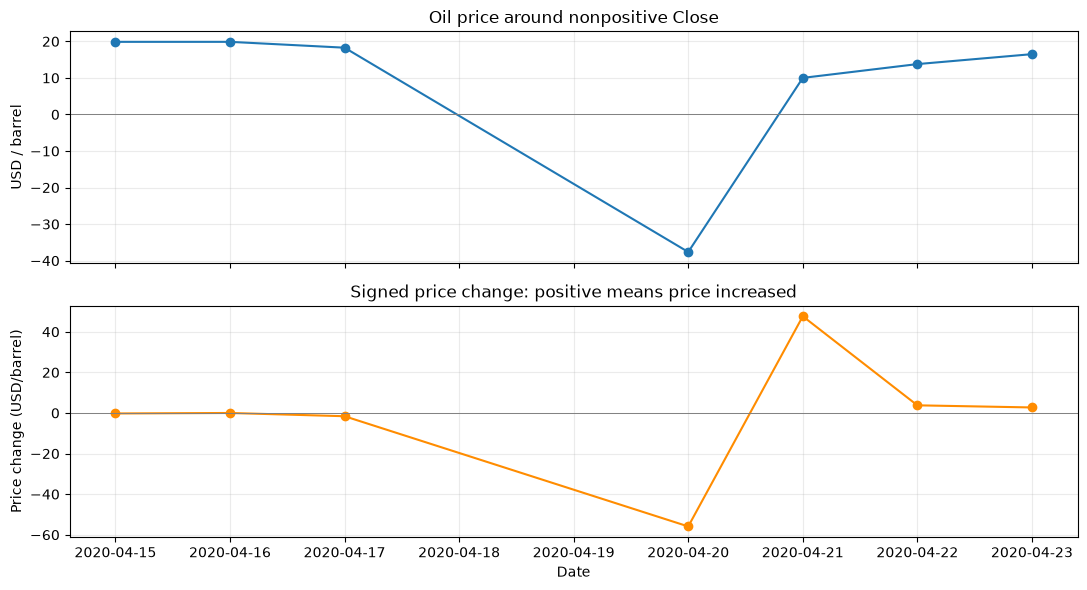

In [17]:
if feature_ready:
    
    review_columns = ['Date', 'Close', 'Price_Change', 'Nonpositive_Pair']
    print('\n15 phiên có thay đổi giá tuyệt đối lớn nhất — Price_Change theo USD/barrel')
    display(oil.loc[oil['Price_Change'].abs().nlargest(15).index, review_columns].sort_values('Date'))

    
    
    event_positions = [position for position, value in enumerate(oil['Close']) if value <= 0]
    if not event_positions:
        print('Không có Close không dương trong snapshot.')
    for position in event_positions:
        context = oil.iloc[max(0, position - 3):position + 4]
        print('\nCác phiên quanh ngày Oil có Close không dương')
        display(context[review_columns])
        fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
        axes[0].plot(context['Date'], context['Close'], marker='o')
        axes[0].set(title='Oil price around nonpositive Close', ylabel='USD / barrel')
        axes[1].plot(context['Date'], context['Price_Change'], marker='o', color='darkorange')
        axes[1].set(title='Signed price change: positive means price increased', xlabel='Date', ylabel='Price change (USD/barrel)')
        for ax in axes:
            ax.axhline(0, color='gray', linewidth=.7)
        plt.tight_layout()
        plt.show()
else:
    print('Chưa rà soát extreme movements: kiểm tra mục 2.0.')